In [6]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import trange, tqdm
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoImageProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

In [40]:
_SIGLIP_ID = "google/siglip-so400m-patch14-384"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModel.from_pretrained(_SIGLIP_ID).to(device).eval()
processor = AutoImageProcessor.from_pretrained(_SIGLIP_ID, backend="torchvision")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 888/888 [00:00<00:00, 17903.01it/s]


In [2]:
'''
inference/trunk_export/
  crops/{key}.png        one per trunk detection, WITH context margin (lossless)
  meta.csv               key, stem, frame, x1..y2, crop offset, conf, depth_q25, box_h
  references.json        the annotator's fg/bg picks as keys (written at filter time)
inference/trunk_embeddings.npz   (already exists) current SigLIP embeddings
'''

DATA_ROOT = Path("../data/ab9cadb8-a4be-4357-b2d6-b781b625a2f9")
INFERENCE_ROOT = DATA_ROOT / "inference"
CROPS_ROOT = INFERENCE_ROOT / "trunk_export/crops"
meta_path = INFERENCE_ROOT / "trunk_export" / "meta.csv"

meta = pd.read_csv(meta_path)
npz = np.load(INFERENCE_ROOT / "trunk_embeddings.npz", allow_pickle=True)
siglip = dict(zip(npz["keys"].astype(str), npz["emb"]))                                  # key -> (1152,)
# print("Available arrays:", npz.files)
# for name in npz.files:
#   arr = npz[name]
#   print(f"\narray {name}:")
#   print("  Shape:", arr.shape)
#   print("  Dtype:", arr.dtype)
#   print("  Values:\n", arr[:5] if arr.ndim > 0 else arr)

refs = json.loads((INFERENCE_ROOT / "trunk_export/references.json").read_text())
meta["ref"] = meta["key"].map({**{k: "fg" for k in refs["fg"]}, **{k: "bg" for k in refs["bg"]}})  # fg / bg / NaN

In [4]:
# # for _, row in tqdm(meta.iterrows()):
# # for i in tqdm(range(50160)):
#   row = meta.iloc[i]
#   img = Image.open(CROPS_ROOT / f"{row.key}.png").convert("RGB") # this is the
#   bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
#   bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1
#   crop = img.crop((bx1, by1, bx2, by2))
# 
#   with torch.inference_mode():
#     inputs = processor(images=crop, return_tensors="pt").to(device)
#     emb = model.get_image_features(**inputs).pooler_output # (B, D)
#     emb = F.normalize(emb, p=2, dim=-1)

In [6]:
row = meta.iloc[114]
print(row)
img = Image.open(CROPS_ROOT / f"{row.key}.png").convert("RGB") # this is the 
img.mode
bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1

crop = img.crop((bx1, by1, bx2, by2))
crop, siglip[row.key]

key          L_1782121838_p0000_chunk_005_000036_1116_864
stem                  L_1782121838_p0000_chunk_005_000036
frame                                                  36
x1                                                   1116
y1                                                    864
x2                                                   1457
y2                                                   2043
crop_x1                                               946
crop_y1                                               570
conf                                             0.775879
depth_q25                                        0.654821
box_h                                                1179
ref                                                    fg
Name: 114, dtype: object


(<PIL.Image.Image image mode=RGB size=341x1179>,
 array([-0.01749919,  0.0230463 , -0.01573422, ..., -0.00638481,
        -0.01270856, -0.01858864], shape=(1152,), dtype=float32))

In [80]:
# meta[meta['ref'] == "fg"]

In [8]:
with torch.inference_mode():
  inputs = processor(images=crop, return_tensors="pt").to(device)
  emb = model.get_image_features(**inputs).pooler_output # (B, D)
  emb = F.normalize(emb, p=2, dim=-1)

# emb.flatten()
emb.flatten().cpu().numpy(), siglip[row.key]

(array([-0.01782894,  0.02489748, -0.01606014, ..., -0.0071218 ,
        -0.0144208 , -0.01619169], shape=(1152,), dtype=float32),
 array([-0.01749919,  0.0230463 , -0.01573422, ..., -0.00638481,
        -0.01270856, -0.01858864], shape=(1152,), dtype=float32))

In [9]:
w = torch.from_numpy(siglip[row.key])
print(float(emb.flatten().cpu() @ w))          # cosine similarity (both are L2-normalized)

0.9986809492111206


In [10]:
fg_bank, bg_bank = [], []
for stem in refs['fg']:
  # print(f"{stem}: {siglip[stem]}")
  fg_bank.append(siglip[stem])

for stem in refs['bg']:
  bg_bank.append(siglip[stem])

fg_bank = torch.from_numpy(np.array(fg_bank))
bg_bank = torch.from_numpy(np.array(bg_bank))

In [4]:
from collections import Counter

SIGLIP_FLOOR  = 0.0    # tune: if BOTH prototype sims are below this → "looks like neither" → unknown
SIGLIP_MARGIN = 0.02 # |a - b| below this → too ambiguous → unknown
SIGLIP_TOPK = 3
def _topk_score(v, bank):
  """Mean of the top-k cosine similarities between v (D,) and the bank rows (K, D)."""
  import torch
  sims = bank @ v # (K,) cosine, all unit vectors
  return float(torch.topk(sims, k=min(SIGLIP_TOPK, len(sims))).values.mean())

def decide(a, b):                                   # identical to _siglip_class2
    if a < SIGLIP_FLOOR and b < SIGLIP_FLOOR: return "unknown"
    if abs(a - b) < SIGLIP_MARGIN:            return "unknown"
    return "foreground" if a > b else "background"

In [6]:
SIGLIP_FLOOR  = 0.0    # tune: if BOTH prototype sims are below this → "looks like neither" → unknown
SIGLIP_MARGIN = 0.02 # |a - b| below this → too ambiguous → unknown
SIGLIP_TOPK = 3
def _topk_score(v, bank):
  """Mean of the top-k cosine similarities between v (D,) and the bank rows (K, D)."""
  import torch
  sims = bank @ v # (K,) cosine, all unit vectors
  return float(torch.topk(sims, k=min(SIGLIP_TOPK, len(sims))).values.mean())

# hits = {"fg": 0, "bg": 0, "unknown":0}
# for name, own, other in (("fg", fg_bank, bg_bank), ("bg", bg_bank, fg_bank)):
#   for i in range(len(own)):
#     rest = torch.cat([own[:i], own[i+1:]])
#     a, b = _topk_score(own[i], rest), _topk_score(own[i], other)
#     if a < SIGLIP_FLOOR and b < SIGLIP_FLOOR:
#         hits["unknown"] += 1
#     if abs(a - b) < SIGLIP_MARGIN:
#         hits["unknown"] += 1
#     hits[name] += int(a > b)

# hits

from collections import Counter

def decide(a, b):                                   # identical to _siglip_class2
    if a < SIGLIP_FLOOR and b < SIGLIP_FLOOR: return "unknown"
    if abs(a - b) < SIGLIP_MARGIN:            return "unknown"
    return "foreground" if a > b else "background"

conf = Counter()
for label, own, other in (("foreground", fg_bank, bg_bank), ("background", bg_bank, fg_bank)):
    for i in range(len(own)):
        rest = torch.cat([own[:i], own[i+1:]])
        fg_b, bg_b = (rest, other) if label == "foreground" else (other, rest)   # bank roles, not own/other
        a, b = _topk_score(own[i], fg_b), _topk_score(own[i], bg_b)
        conf[(label, decide(a, b))] += 1

pd.Series(conf).unstack(fill_value=0)               # rows = true label, cols = decision

NameError: name 'fg_bank' is not defined

In [12]:
# references se apostasi ligotero apo 30 frames
r = meta[meta.ref.notna()].sort_values("frame")
print(r.groupby("ref")["frame"].apply(lambda f: f.diff().lt(30).sum()))   # refs within 30 frames of another ref

ref
bg    24
fg    19
Name: frame, dtype: int64


In [13]:
def _siglip_class2(v, fg_bank, bg_bank):
  if v is None:
    return "unknown"
  a, b = _topk_score(v, fg_bank), _topk_score(v, bg_bank)
  if a < SIGLIP_FLOOR and b < SIGLIP_FLOOR:
    return "unknown"
  if abs(a - b) < SIGLIP_MARGIN:
    return "unknown"
  return "foreground" if a > b else "background"

dec = {str(k): _siglip_class2(torch.from_numpy(v), fg_bank, bg_bank) for k, v in siglip.items()}
meta["siglip"] = meta.key.map(dec)
meta["depth_bin"] = pd.cut(meta.depth_q25, [0, 1.0, 1.5, 2.5, 3.5, 5, 100])
pd.crosstab(meta.depth_bin, meta.siglip, normalize="index").round(2)

siglip,background,foreground,unknown
depth_bin,,,
"(0.0, 1.0]",0.24,0.31,0.45
"(1.0, 1.5]",0.94,0.02,0.04
"(1.5, 2.5]",0.99,0.00,0.01
"(2.5, 3.5]",1.00,0.00,0.00
"(3.5, 5.0]",1.00,0.00,0.00
"(5.0, 100.0]",1.00,0.00,0.00


In [ ]:
dec

In [58]:
_DINO_ID = "facebook/dinov2-base"
dino_model = AutoModel.from_pretrained(_DINO_ID).to(device).eval()
dino_processor = AutoImageProcessor.from_pretrained(_DINO_ID)
# dino_model

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 22144.27it/s]


In [8]:
# dino_model(torch.zeros(2,3,28,28, device=device)).pooler_output

In [9]:
# from itertools import islice
# dinov2 = dict()

# for _, row in islice(meta.iterrows(), 3):
#   print(row.key)
#   img_path = CROPS_ROOT / f"{row.key}.png"
#   img = Image.open(img_path).convert("RGB")
#   bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
#   bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1
#   crop = img.crop((bx1, by1, bx2, by2))

#   with torch.inference_mode():
#     inputs = processor(images=crop, return_tensors="pt").to(device)
#     emb = model(**inputs).pooler_output # (B, D)
#     emb = F.normalize(emb, p=2, dim=-1)

#   dinov2[row.key] = emb.cpu().numpy()

In [59]:
def tight_crop(r):
    img = Image.open(CROPS_ROOT / f"{r.key}.png").convert("RGB")
    bx1, by1 = r.x1 - r.crop_x1, r.y1 - r.crop_y1
    return img.crop((bx1, by1, bx1 + (r.x2 - r.x1), by1 + (r.y2 - r.y1)))

def pad_square(img, fill=(124, 116, 104)):            # ~ImageNet mean gray
    w, h = img.size; s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill); canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

def embed_all(model, proc, crop_fn=tight_crop, pad=True, bs=64, **proc_kw):
    rows, keys, feats = list(meta.itertuples(index=False)), [], []
    for i in tqdm(range(0, len(rows), bs)):
        batch = rows[i:i + bs]
        imgs = [crop_fn(r) for r in batch]
        if pad:
            imgs = [pad_square(im) for im in imgs]
        with torch.inference_mode():
            inp = proc(images=imgs, return_tensors="pt", **proc_kw).to(device)
            out = model(**inp)
            e = out.pooler_output if hasattr(out, "pooler_output") else out # (B, D)
            feats.append(F.normalize(e, p=2, dim=-1).cpu())
        keys += [r.key for r in batch]
    return dict(zip(keys, torch.cat(feats)))

proc_kw = {
  'size':{"height": 224, "width": 224},
  'do_center_crop':False,
  "do_normalize": True,
  "do_rescale": True,
  "image_mean": [0.30873852713668126, 0.40787950169456705, 0.2226692956750353],
  "image_std":  [0.11958446534026305, 0.13250266414996473, 0.10012729012265584]
}
dino = embed_all(dino_model, dino_processor, pad=False, **proc_kw)
np.savez(f"{INFERENCE_ROOT}/dinov2_tight_embeddings_custom_norm.npz", keys=np.array(list(dino)), emb=torch.stack(list(dino.values())).numpy())

100%|██████████| 784/784 [02:36<00:00,  5.03it/s]


In [ ]:
dino_npz = np.load(INFERENCE_ROOT / "dinov2_tight_embeddings.npz", allow_pickle=True)
dino = dict(zip(dino_npz["keys"].astype(str), dino_npz["emb"]))
# NOTE: How to populate meta from this, so not to run the embed_all each time ??

In [61]:
def banks(emb_by_key):
  fg = torch.stack([emb_by_key[k] for k in refs["fg"] if k in emb_by_key])
  bg = torch.stack([emb_by_key[k] for k in refs["bg"] if k in emb_by_key])
  assert len(fg) == len(refs["fg"]) and len(bg) == len(refs["bg"]), "missing reference keys"
  return fg, bg

def classify_all(emb_by_key):
  fg_b, bg_b = banks(emb_by_key)
  return {k: decide(_topk_score(v, fg_b), _topk_score(v, bg_b)) for k, v in emb_by_key.items()}

meta["dinov2"] = meta.key.map(classify_all(dino))
# meta["dinov2"] = meta.key.map(classify_all({k: torch.from_numpy(v) for k, v in dino.items()}))
meta["siglip"] = meta.key.map(classify_all({k: torch.from_numpy(v) for k, v in siglip.items()}))
pop = meta[meta.ref.isna()] # exclude references themselves (they match their own copy at 1.0)
print(pop.dinov2.value_counts(), pop.siglip.value_counts())
pd.crosstab(pop.siglip, pop.dinov2)                    # how decisions moved between models
pd.crosstab(pd.cut(pop.depth_q25, [0, 1.0, 1.5, 2.5, 3.5, 5, 100]), pop.dinov2, normalize="index").round(2)

dinov2
background    41242
foreground     5247
unknown        3571
Name: count, dtype: int64 siglip
background    41401
unknown        5282
foreground     3377
Name: count, dtype: int64


dinov2,background,foreground,unknown
depth_q25,,,
"(0.0, 1.0]",0.34,0.46,0.20
"(1.0, 1.5]",0.89,0.04,0.06
"(1.5, 2.5]",0.96,0.01,0.03
"(2.5, 3.5]",0.99,0.00,0.01
"(3.5, 5.0]",0.99,0.00,0.01
"(5.0, 100.0]",0.99,0.00,0.01


In [16]:
# dinov2 no padding
# background    41213
# foreground     6196
# unknown        2651

# dinov2 padding
# background    40619
# foreground     4947
# unknown        4494

In [62]:
fg_b, bg_b = banks(dino)
gap = pd.Series({k: _topk_score(v, fg_b) - _topk_score(v, bg_b) for k, v in dino.items()})
print(f"gap description: {gap.describe()}\n")
print(f"gap quantiles:\n{gap.abs().quantile([0.05, 0.1, 0.2])}")

gap description: count    50002.000000
mean        -0.075953
std          0.071399
min         -0.321590
25%         -0.122026
50%         -0.086478
75%         -0.044104
max          0.342291
dtype: float64

gap quantiles:
0.05    0.014510
0.10    0.027354
0.20    0.047982
dtype: float64


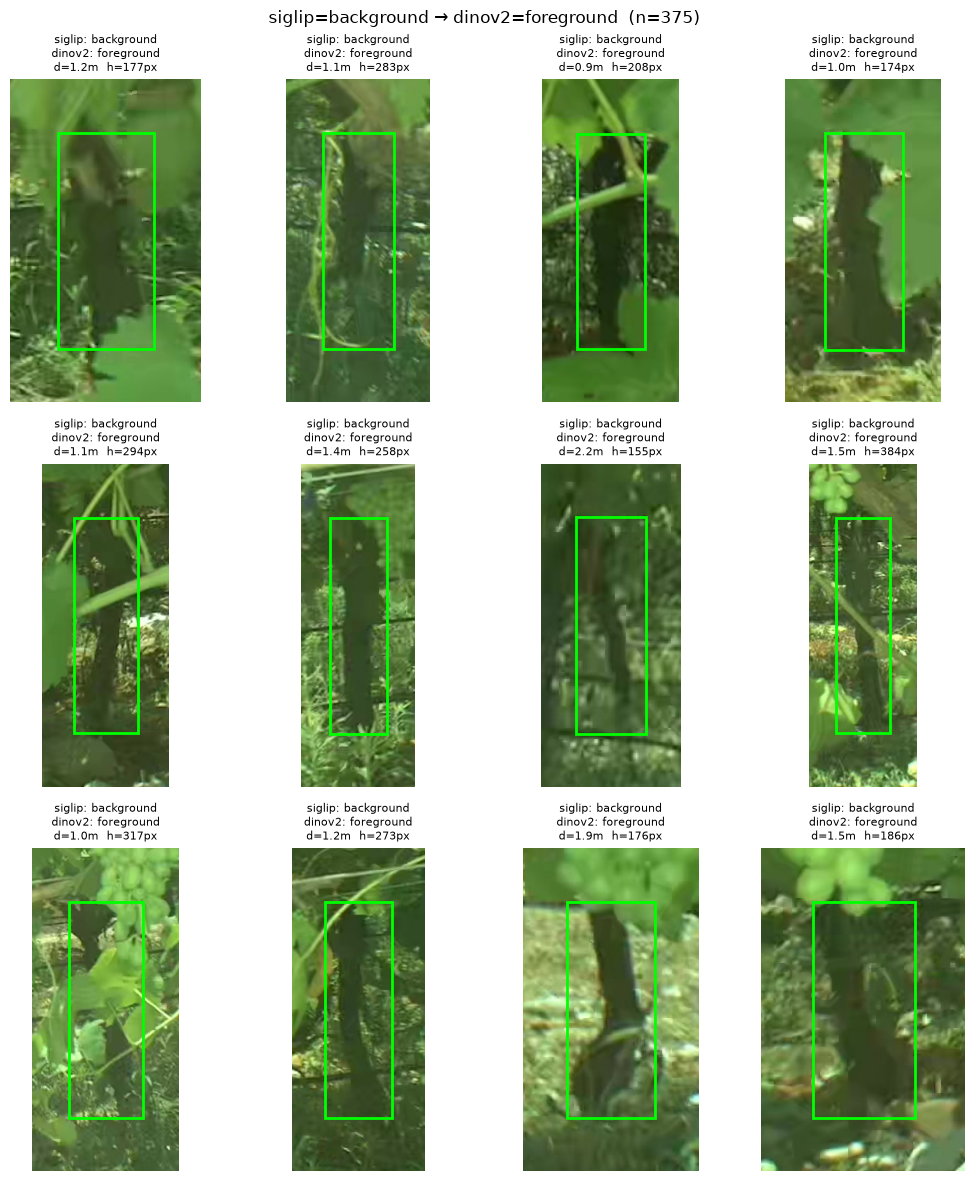

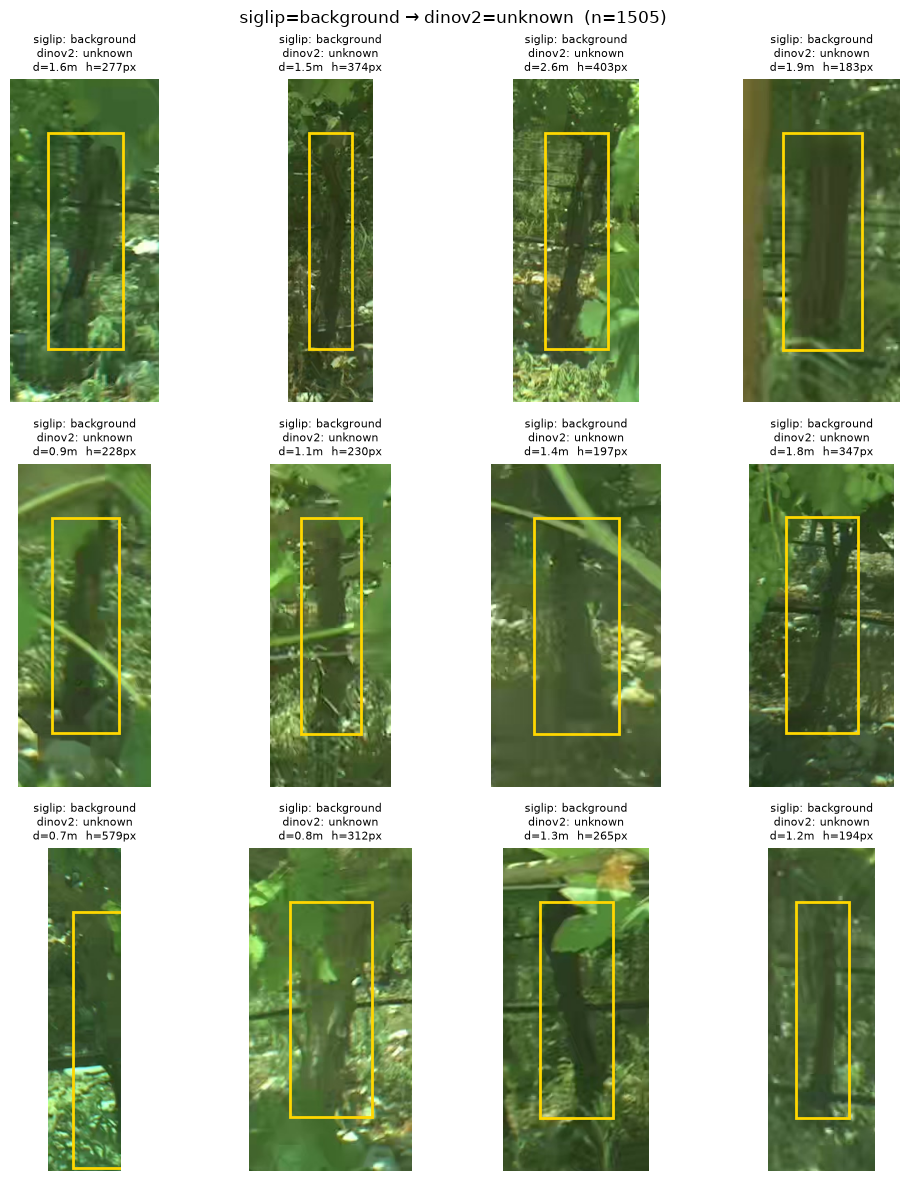

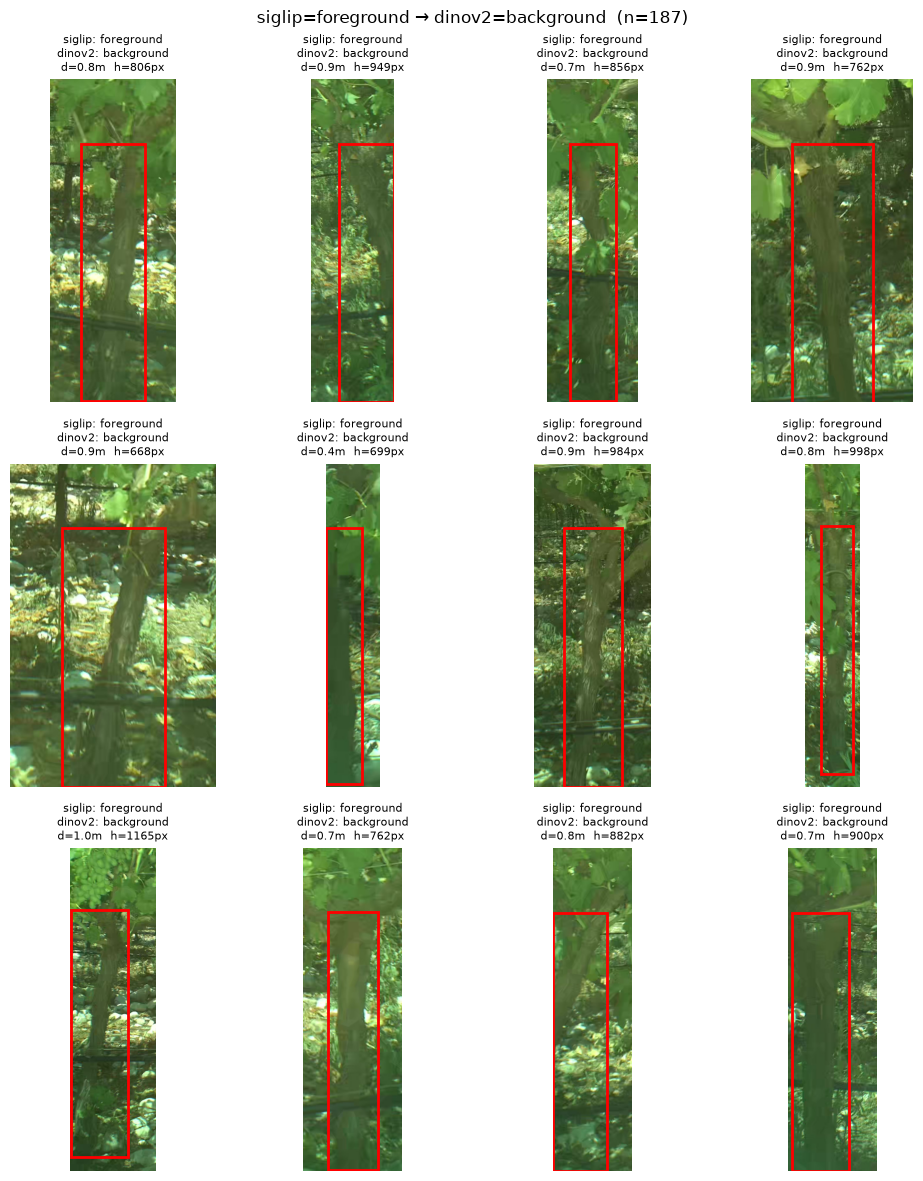

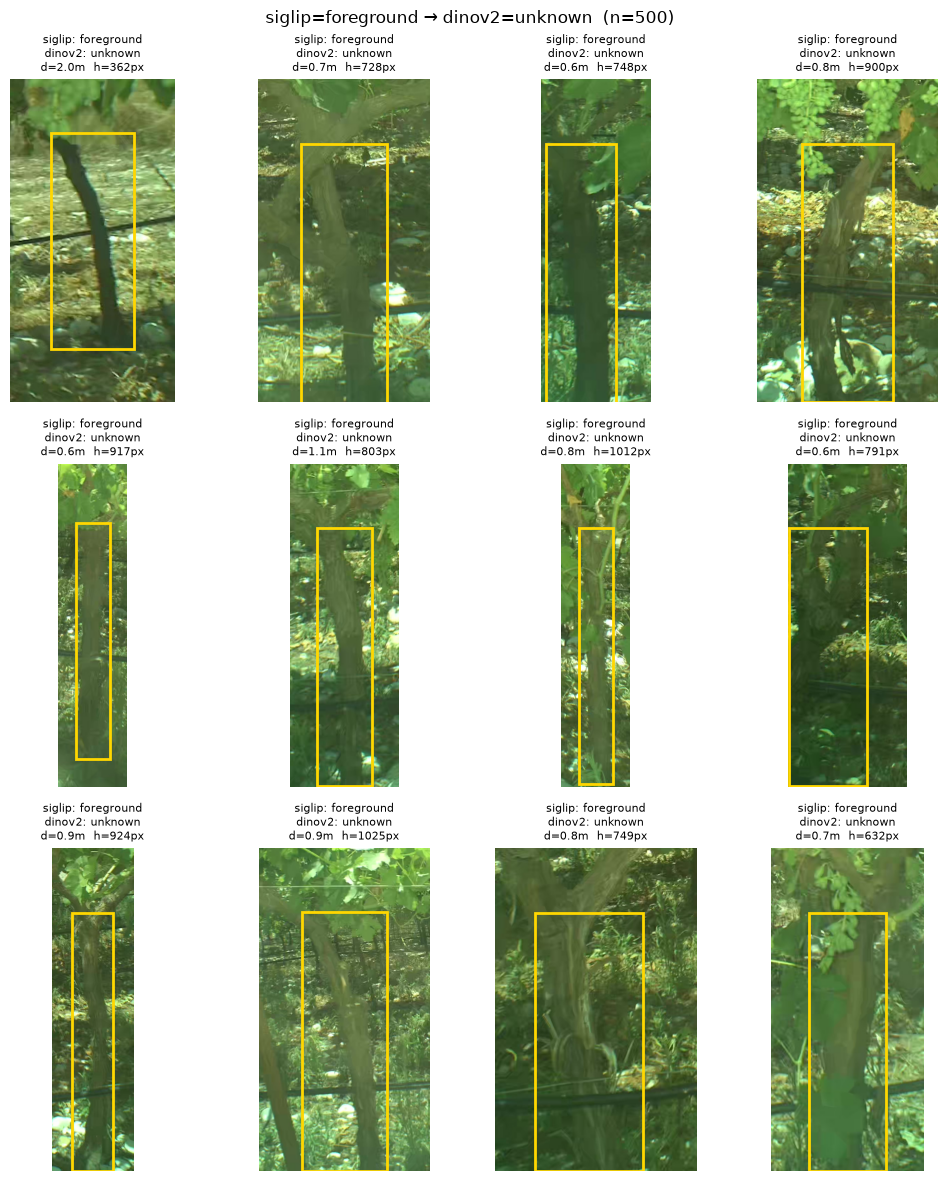

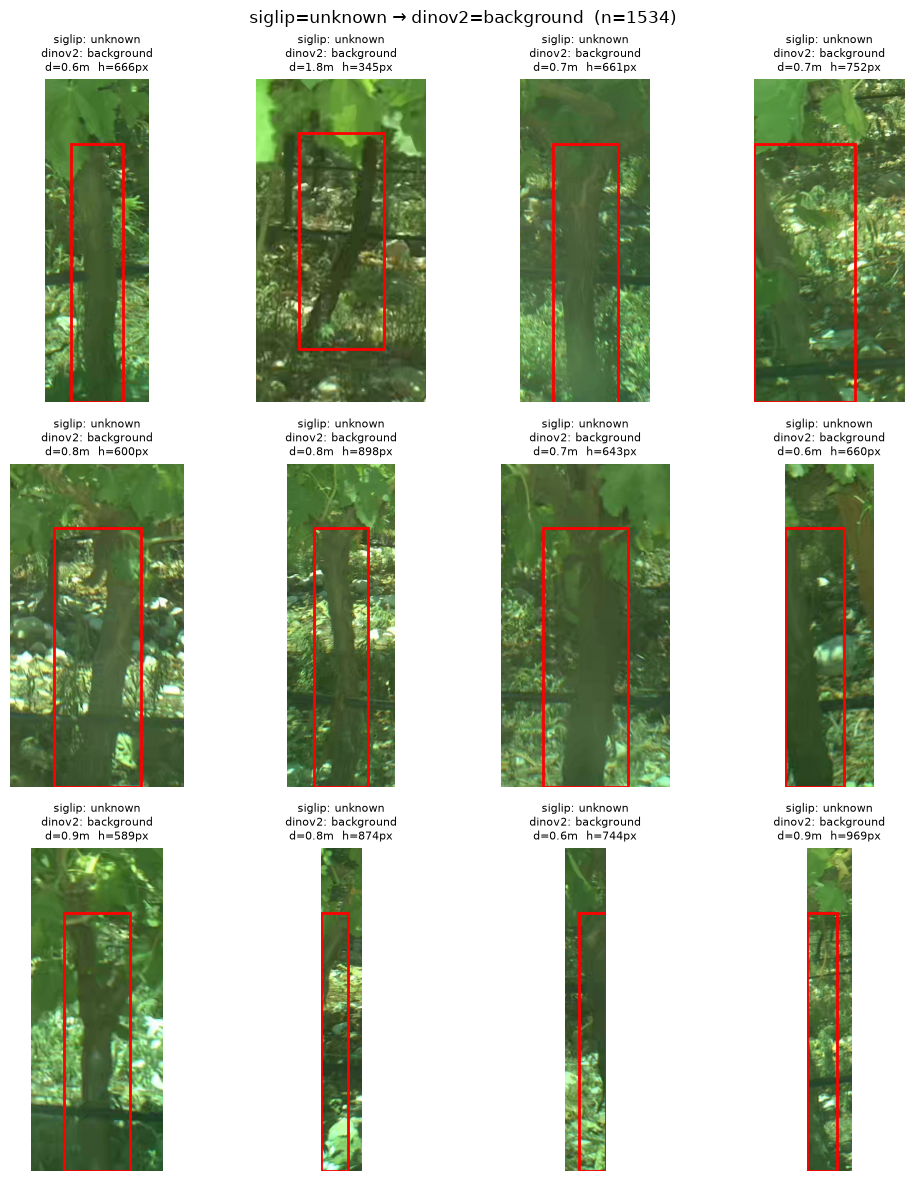

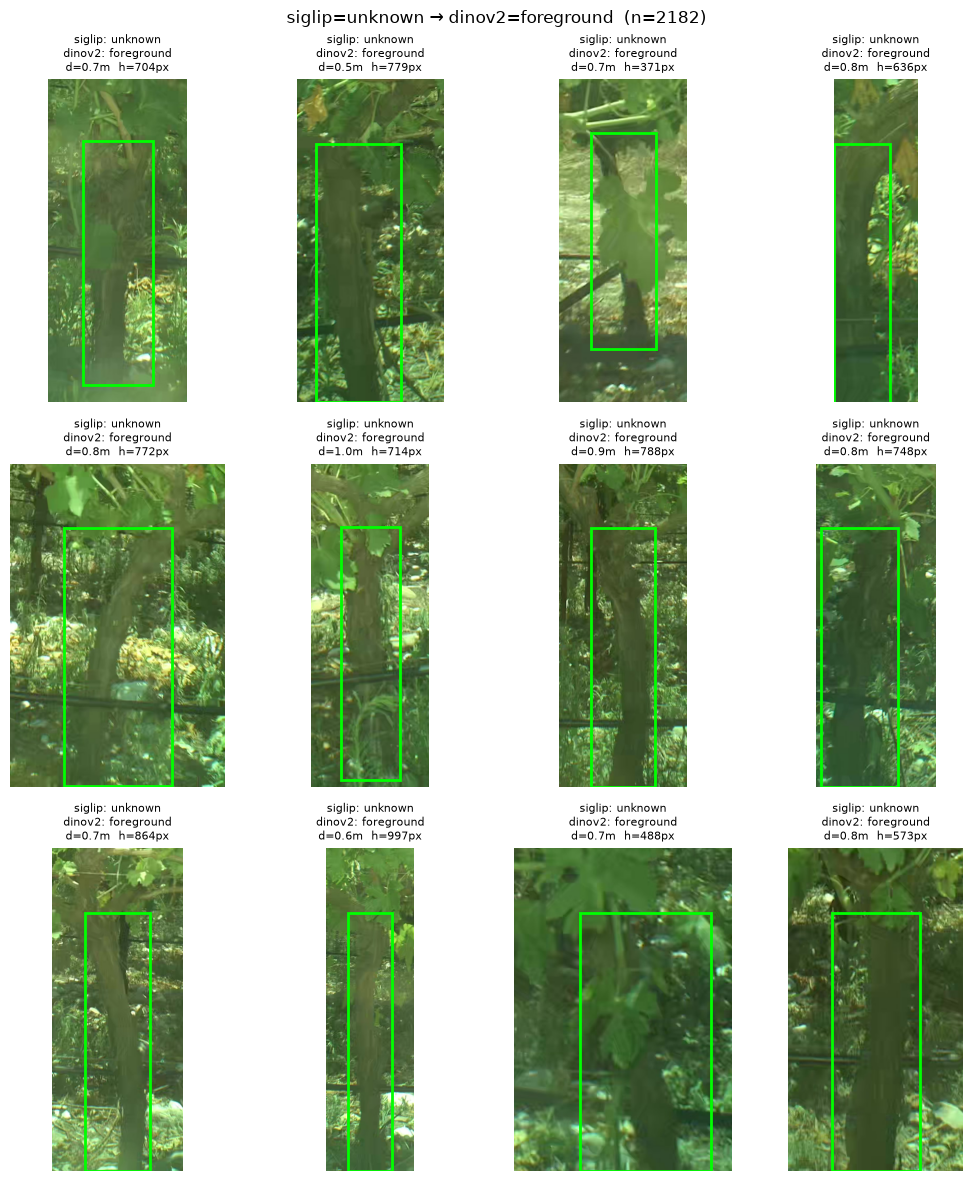

In [63]:
# 1. Trunks where the models disagree
import re, json
import matplotlib.pyplot as plt, matplotlib.patches as patches

COL = {"foreground": "lime", "background": "red", "unknown": "gold", "missing": "gray"}
MODELS = ("siglip", "dinov2")
ref_keys = set(refs["fg"]) | set(refs["bg"])
pop = meta[meta.ref.isna()].copy()          # leave the references out of the stats


def show_crops(df, models=MODELS, n=12, ncols=4, title=""):
    df = df.sample(min(n, len(df)), random_state=0)
    nrows = -(-len(df) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 4 * nrows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, r in zip(axes.flat, df.itertuples()):
        ax.imshow(Image.open(CROPS_ROOT / f"{r.key}.png").convert("RGB"))
        ax.add_patch(patches.Rectangle((r.x1 - r.crop_x1, r.y1 - r.crop_y1), r.x2 - r.x1, r.y2 - r.y1,
                                       fill=False, lw=2, ec=COL[getattr(r, models[-1])]))
        ax.set_title("\n".join(f"{m}: {getattr(r, m)}" for m in models)
                     + f"\nd={r.depth_q25:.1f}m  h={r.box_h}px", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

for (a, b), grp in pop[pop.siglip != pop.dinov2].groupby(["siglip", "dinov2"]):
    show_crops(grp, title=f"siglip={a} → dinov2={b}  (n={len(grp)})")


TypeError: unhashable type: 'Series'

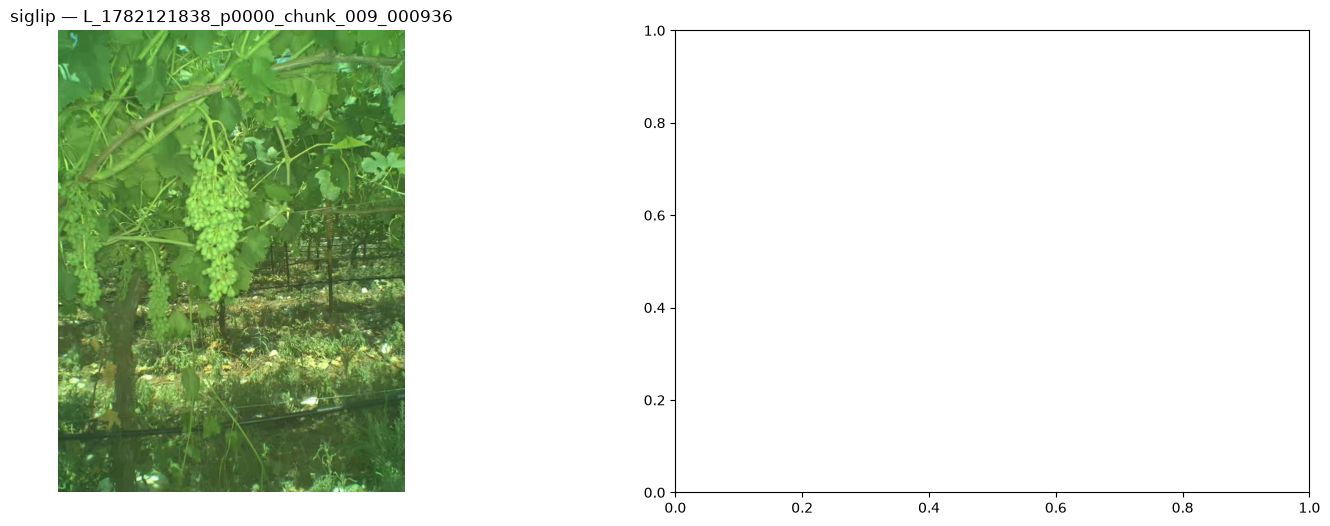

In [64]:
# 2. The same frame side by side, one panel per model in preview images
PREVIEW = INFERENCE_ROOT / "preview"
sidecars = [p for p in sorted(PREVIEW.glob("frame_*.json")) if re.fullmatch(r"frame_\d+\.json", p.name)]          # skip _fg/_debug variants
by_stem = {json.loads(p.read_text())["src_stem"]: p for p in sidecars}
dec = meta.set_index("key")[list(MODELS)]

def show_frame(sc_path, models=MODELS):
    sc = json.loads(sc_path.read_text())
    img = Image.open(sc_path.with_suffix(".jpg")).convert("RGB")
    fig, axes = plt.subplots(1, len(models), figsize=(9 * len(models), 6), squeeze=False)
    for ax, m in zip(axes[0], models):
        ax.imshow(img); ax.axis("off"); ax.set_title(f"{m} — {sc['src_stem']}")
        for b in sc["boxes"]:
            if b.get("cls_name") != "trunk": continue
            x1, y1, x2, y2 = b["xyxy"]
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                           lw=3 if b["key"] in ref_keys else 1.5,
                                           ec=COL[dec[m].get(b["key"], "missing")]))
    plt.tight_layout(); plt.show()

# preview frames with the most disagreements first
pop["disagree"] = pop.siglip != pop.dinov2
worst = pop.groupby("stem").disagree.sum().sort_values(ascending=False)
for stem in [s for s in worst.index if s in by_stem][:5]:
    show_frame(by_stem[stem])

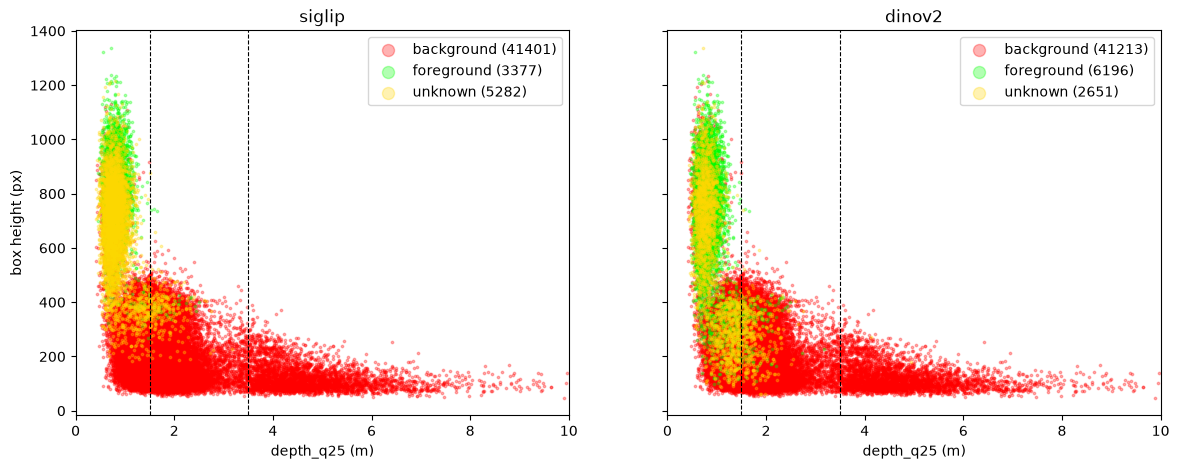

In [ ]:
# 3. Where each model puts fg/bg overall
fig, axes = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 5), sharey=True)
for ax, m in zip(axes, MODELS):
    for c, g in pop.groupby(m):
        ax.scatter(g.depth_q25, g.box_h, s=3, alpha=0.3, c=COL[c], label=f"{c} ({len(g)})")
    for x in (1.5, 3.5): ax.axvline(x, ls="--", c="k", lw=0.8)
    ax.set_xlim(0, 10); ax.set_xlabel("depth_q25 (m)"); ax.set_title(m); ax.legend(markerscale=5)
axes[0].set_ylabel("box height (px)")
plt.show()

In [28]:
# # key -> (preview jpg, box xyxy in jpg coords), for every trunk on a preview frame
# box_by_key = {}
# for p in sidecars:
#     for b in json.loads(p.read_text())["boxes"]:
#         if b.get("cls_name") == "trunk":
#             box_by_key[b["key"]] = (p.with_suffix(".jpg"), b["xyxy"])

# def show_frame_and_crop(df, models=MODELS, n=6, title=""):
#     df = df[df.key.isin(box_by_key)]
#     if df.empty:
#         print(f"{title}: no trunks on preview frames"); return
#     df = df.sample(min(n, len(df)), random_state=0)
#     fig, axes = plt.subplots(len(df), 2, figsize=(14, 4.5 * len(df)), squeeze=False,
#                              gridspec_kw={"width_ratios": [3, 1]})
#     for (ax_f, ax_c), r in zip(axes, df.itertuples()):
#         ec = COL[getattr(r, models[-1])]
#         label = "  |  ".join(f"{m}: {getattr(r, m)}" for m in models)

#         # full frame, target trunk outlined (black underlay so it stands out on foliage)
#         jpg, (x1, y1, x2, y2) = box_by_key[r.key]
#         ax_f.imshow(Image.open(jpg).convert("RGB")); ax_f.axis("off")
#         for lw, c in ((4.5, "black"), (2.5, ec)):
#             ax_f.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=lw, ec=c))
#         ax_f.set_title(f"{r.stem}   —   {label}", fontsize=9)

#         # context crop, same as before
#         ax_c.imshow(Image.open(CROPS_ROOT / f"{r.key}.png").convert("RGB")); ax_c.axis("off")
#         ax_c.add_patch(patches.Rectangle((r.x1 - r.crop_x1, r.y1 - r.crop_y1), r.x2 - r.x1, r.y2 - r.y1,
#                                          fill=False, lw=2, ec=ec))
#         ax_c.set_title(f"d={r.depth_q25:.1f}m  h={r.box_h}px", fontsize=9)
#     fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

# for (a, b), grp in pop[pop.siglip != pop.dinov2].groupby(["siglip", "dinov2"]):
#     show_frame_and_crop(grp, title=f"siglip={a} → dinov2={b}  (n={len(grp)} total)")


In [55]:
print(dino_processor.image_mean)
print(dino_processor.image_std)
print("do_rescale:", dino_processor.do_rescale)
print("rescale_factor:", dino_processor.rescale_factor)
print("do_normalize:", dino_processor.do_normalize)
print("image_mean:", dino_processor.image_mean)
print("image_std:", dino_processor.image_std)

(0.485, 0.456, 0.406)
(0.229, 0.224, 0.225)
do_rescale: True
rescale_factor: 0.00392156862745098
do_normalize: True
image_mean: (0.485, 0.456, 0.406)
image_std: (0.229, 0.224, 0.225)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7930381..5.9226313].


key = L_1782121838_p0000_chunk_005_000001_162_1105


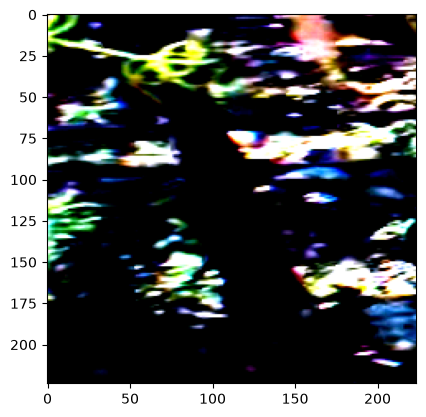

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7538723..5.9226313].


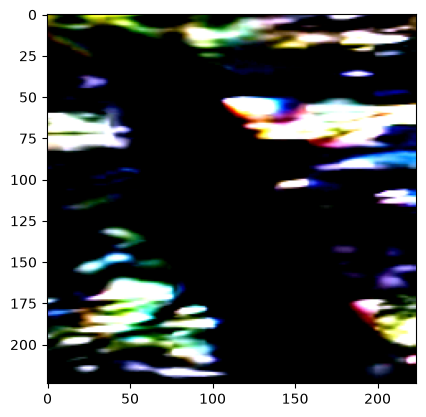

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.2238624..6.235958].


key = L_1782121838_p0000_chunk_005_000001_1021_1036


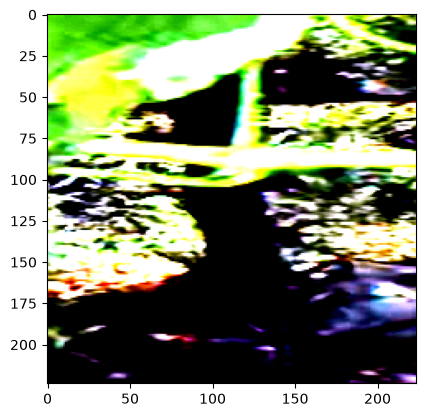

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.3194149..5.780529].


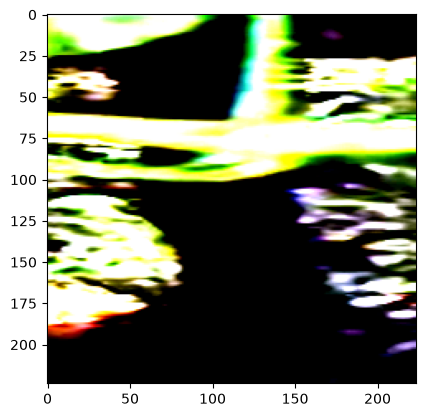

In [57]:
# Fix model input!
from itertools import islice
import matplotlib.pyplot as plt

# proc_kw = {'do_center_crop':False, 'size':{"height": 224, "width": 224}}
# proc_kw = dict()
proc_kw = {
  'size':{"height": 224, "width": 224},
  'do_center_crop':False,
  "do_normalize": True,
  "do_rescale": True,
  "image_mean": [0.30873852713668126, 0.40787950169456705, 0.2226692956750353],
  "image_std":  [0.11958446534026305, 0.13250266414996473, 0.10012729012265584]
}

for _, row in islice(meta.iterrows(), 2):
  print(f"key = {row.key}")
  img_path = CROPS_ROOT / f"{row.key}.png"
  img = Image.open(img_path).convert("RGB")
  bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
  bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1
  crop = img.crop((bx1, by1, bx2, by2))
  # proc_img = dino_processor(images=img, return_tensors="pt", **proc_kw).to(device)
  # proc_crop = dino_processor(images=img, return_tensors="pt", **proc_kw).to(device)
  proc_img = processor(images=img, return_tensors="pt", **proc_kw).to(device) # siglip pre-processing
  proc_crop = processor(images=crop, return_tensors="pt", **proc_kw).to(device) # siglip pre-processing
  # print(proc_img)

  # plt.imshow(img)
  # plt.show()
  plt.imshow(proc_img['pixel_values'].cpu().squeeze(0).permute(1,2,0))
  plt.show()
  # plt.imshow(crop)
  # plt.show()
  plt.imshow(proc_crop['pixel_values'].cpu().squeeze(0).permute(1,2,0))
  plt.show()

In [ ]:
import torchvision.transforms.v2 as v2

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sum_sq = torch.zeros(3, dtype=torch.float64)
num_pixels = 0

transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

for _, row in tqdm(meta.iterrows(), total=len(meta)):
    img_path = CROPS_ROOT / f"{row.key}.png"
    img = Image.open(img_path).convert("RGB")

    bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1
    bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1

    crop = img.crop((bx1, by1, bx2, by2))
    pixels = transforms(crop).to(torch.float64)  # [C, H, W]

    channel_sum += pixels.sum(dim=(1, 2))
    channel_sum_sq += (pixels ** 2).sum(dim=(1, 2))
    num_pixels += pixels.shape[1] * pixels.shape[2]

mean = channel_sum / num_pixels
std = (channel_sum_sq / num_pixels - mean ** 2).clamp(min=0).sqrt()

print("Mean:", mean.tolist())
print("Std: ", std.tolist())

  0%|          | 0/50160 [00:00<?, ?it/s]/home/kpetrakis/trunk-filtering/.venv/lib/python3.11/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(
100%|██████████| 50160/50160 [01:11<00:00, 701.25it/s] 

Mean: [0.30873852713668126, 0.40787950169456705, 0.2226692956750353]
Std:  [0.11958446534026305, 0.13250266414996473, 0.10012729012265584]


(0.485, 0.456, 0.406)
(0.229, 0.224, 0.225)
